# Experiment 08 — MNIST CNN: 8 vs. 2

The interactive companion to `experiments/08_mnist_cnn_8_vs_2/train.py`.

**Goal:** experiment 04 asked "is this an 8?" across all of MNIST -- a task
where a do-nothing "always not-8" model scores ~90% accuracy. This
experiment filters the dataset down to ONLY digits 8 and 2, giving a
genuinely balanced task (~50/50). A model that always guesses one class now
scores ~50%, not ~90% -- accuracy here directly reflects real
discriminative skill, and precision/recall stop being the load-bearing
metrics they were in experiment 04.

In [1]:
import sys
from pathlib import Path

import torch
from torch import nn
from torch.utils.data import DataLoader, Subset, random_split
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

REPO_ROOT = Path.cwd().parent
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from utils import get_device, set_seed

# Override the Agg backend that utils.plotting sets, so plots render inline here.
%matplotlib inline

set_seed(42)
device = get_device()
print(f"device: {device}")

POS_CLASS = 8  # logit > 0 means "this is an 8"
NEG_CLASS = 2
DATA_ROOT = REPO_ROOT / "data" / "raw"

device: cpu


## Data

MNIST filtered to only digits 2 and 8 -- a genuinely balanced binary task,
unlike experiment 04's 8-vs-everything.

In [2]:
def filter_to_two_classes(dataset):
    targets = dataset.targets
    mask = (targets == POS_CLASS) | (targets == NEG_CLASS)
    indices = mask.nonzero().squeeze(1).tolist()
    return Subset(dataset, indices)


transform = transforms.ToTensor()
train_all = datasets.MNIST(DATA_ROOT, train=True, download=True, transform=transform)
test_all = datasets.MNIST(DATA_ROOT, train=False, download=True, transform=transform)

train_full = filter_to_two_classes(train_all)
test_set = filter_to_two_classes(test_all)

val_size = 1000
n_train = len(train_full) - val_size
generator = torch.Generator().manual_seed(42)
train_set, val_set = random_split(train_full, [n_train, val_size], generator=generator)

batch_size = 128
train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_set, batch_size=batch_size)
test_loader = DataLoader(test_set, batch_size=batch_size)

print(f"train: {len(train_set)}  val: {len(val_set)}  test: {len(test_set)}")

test_targets = test_all.targets[test_set.indices]
majority_baseline = max(
    (test_targets == POS_CLASS).float().mean().item(),
    (test_targets == NEG_CLASS).float().mean().item(),
)
print(f"majority-class baseline: {majority_baseline:.4f}  (vs. experiment 04's ~0.90)")

train: 10809  val: 1000  test: 2006
majority-class baseline: 0.5145  (vs. experiment 04's ~0.90)


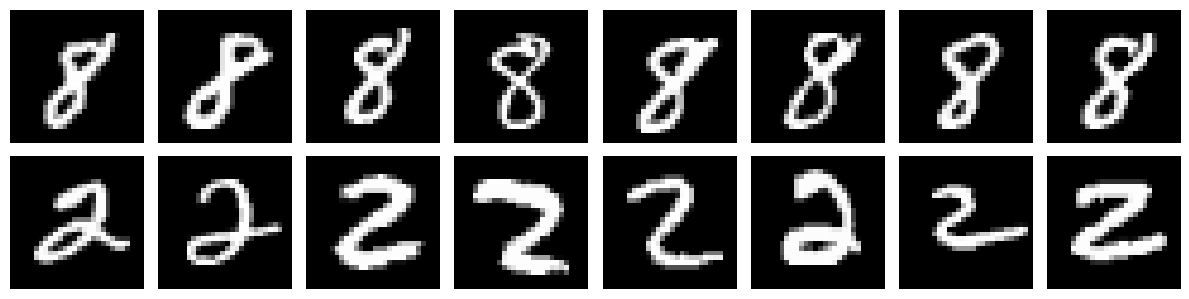

In [3]:
# A peek at the two classes
fig, axes = plt.subplots(2, 8, figsize=(12, 3.2))
shown = {POS_CLASS: 0, NEG_CLASS: 0}
i = 0
while min(shown.values()) < 8:
    img, label = train_full[i]
    if shown[label] < 8:
        row = 0 if label == POS_CLASS else 1
        axes[row, shown[label]].imshow(img.squeeze(0), cmap="gray")
        axes[row, shown[label]].axis("off")
        shown[label] += 1
    i += 1
axes[0, 0].set_ylabel("8", fontsize=12)
axes[1, 0].set_ylabel("2", fontsize=12)
fig.tight_layout()
plt.show()

## Model

Identical architecture to experiment 04 -- this experiment is about the
*data* (balanced pairwise comparison), not the model.

In [4]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 8, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(8, 16, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(16 * 7 * 7, 32),
            nn.ReLU(),
            nn.Linear(32, 1),
        )

    def forward(self, x):
        return self.classifier(self.features(x)).squeeze(1)


model = CNN().to(device)
n_params = sum(p.numel() for p in model.parameters())
print(f"model: CNN, {n_params} parameters")

model: CNN, 26401 parameters


## Training loop

In [5]:
def binary_labels(y):
    return (y == POS_CLASS).float()


@torch.no_grad()
def evaluate(model, loader, loss_fn):
    model.eval()
    total_loss, n = 0.0, 0
    tp = fp = fn = tn = 0
    for x, y in loader:
        x = x.to(device)
        target = binary_labels(y).to(device)
        logits = model(x)
        total_loss += loss_fn(logits, target).item() * x.size(0)
        n += x.size(0)
        pred = (logits > 0).float()
        tp += ((pred == 1) & (target == 1)).sum().item()
        fp += ((pred == 1) & (target == 0)).sum().item()
        fn += ((pred == 0) & (target == 1)).sum().item()
        tn += ((pred == 0) & (target == 0)).sum().item()
    return {
        "loss": total_loss / n,
        "accuracy": (tp + tn) / n,
        "precision": tp / (tp + fp) if (tp + fp) else 0.0,
        "recall": tp / (tp + fn) if (tp + fn) else 0.0,
    }


loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

epochs = 5
train_losses, val_losses, val_accuracies = [], [], []

for epoch in range(1, epochs + 1):
    model.train()
    running_loss, n_seen = 0.0, 0
    for x, y in train_loader:
        x = x.to(device)
        target = binary_labels(y).to(device)

        logits = model(x)
        loss = loss_fn(logits, target)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * x.size(0)
        n_seen += x.size(0)

    train_loss = running_loss / n_seen
    val_metrics = evaluate(model, val_loader, loss_fn)

    train_losses.append(train_loss)
    val_losses.append(val_metrics["loss"])
    val_accuracies.append(val_metrics["accuracy"])

    print(
        f"epoch {epoch} | train loss {train_loss:.4f} | val loss {val_metrics['loss']:.4f} "
        f"| val acc {val_metrics['accuracy']:.4f} | val precision {val_metrics['precision']:.4f} "
        f"| val recall {val_metrics['recall']:.4f}"
    )

epoch 1 | train loss 0.2824 | val loss 0.1231 | val acc 0.9620 | val precision 0.9776 | val recall 0.9467


epoch 2 | train loss 0.0767 | val loss 0.0861 | val acc 0.9730 | val precision 0.9781 | val recall 0.9684


epoch 3 | train loss 0.0583 | val loss 0.0712 | val acc 0.9750 | val precision 0.9782 | val recall 0.9724


epoch 4 | train loss 0.0444 | val loss 0.0551 | val acc 0.9840 | val precision 0.9900 | val recall 0.9783


epoch 5 | train loss 0.0395 | val loss 0.0469 | val acc 0.9860 | val precision 0.9920 | val recall 0.9803


## Results

In [6]:
test_metrics = evaluate(model, test_loader, loss_fn)
print(f"test accuracy:  {test_metrics['accuracy']:.4f}  (majority-class baseline: {majority_baseline:.4f})")
print(f"test precision: {test_metrics['precision']:.4f}")
print(f"test recall:    {test_metrics['recall']:.4f}")

test accuracy:  0.9920  (majority-class baseline: 0.5145)
test precision: 0.9878
test recall:    0.9959


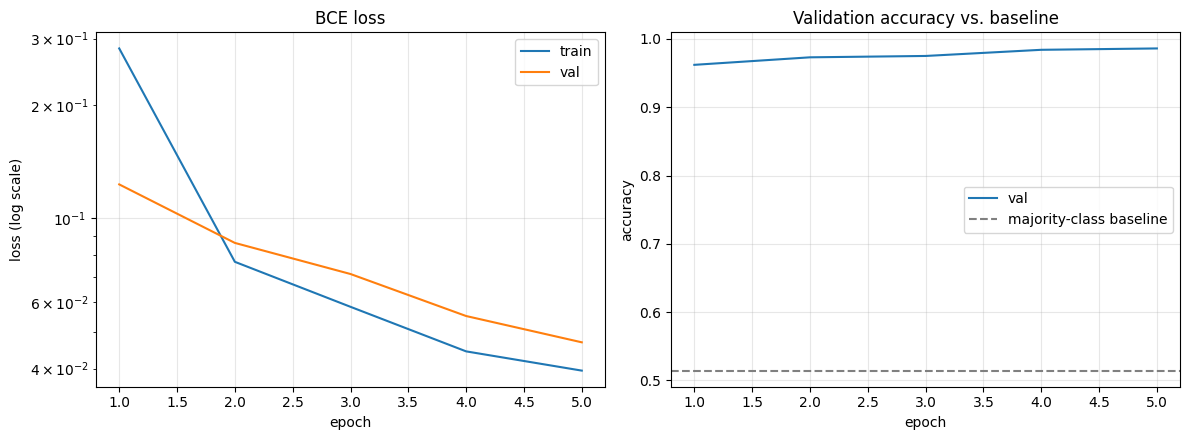

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(range(1, epochs + 1), train_losses, label="train")
axes[0].plot(range(1, epochs + 1), val_losses, label="val")
axes[0].set_yscale("log")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("loss (log scale)")
axes[0].set_title("BCE loss"); axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(range(1, epochs + 1), val_accuracies, label="val")
axes[1].axhline(majority_baseline, color="gray", linestyle="--", label="majority-class baseline")
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("accuracy")
axes[1].set_title("Validation accuracy vs. baseline"); axes[1].legend(); axes[1].grid(True, alpha=0.3)

fig.tight_layout()
plt.show()

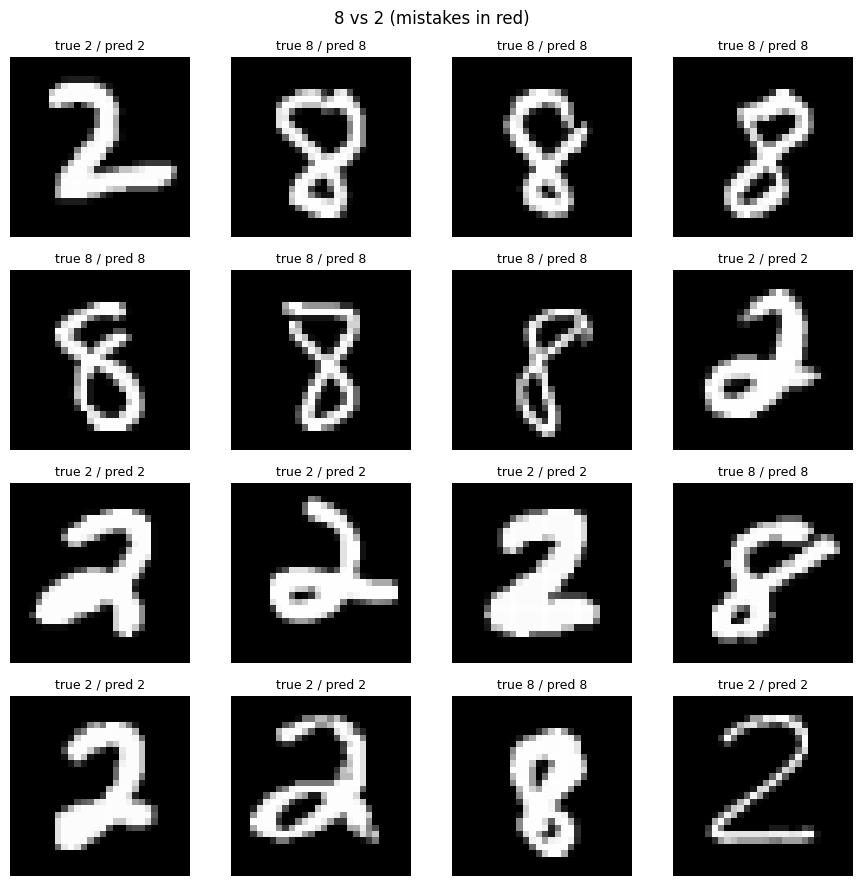

In [8]:
# Sample test predictions, mistakes highlighted in red
model.eval()
x_sample, y_sample = next(iter(DataLoader(test_set, batch_size=64, shuffle=True)))
with torch.no_grad():
    logits = model(x_sample.to(device))
    preds = (logits > 0).cpu().long()
true_is_8 = (y_sample == POS_CLASS).long()

fig, axes = plt.subplots(4, 4, figsize=(9, 9))
for i, ax in enumerate(axes.flat):
    correct = preds[i] == true_is_8[i]
    ax.imshow(x_sample[i, 0], cmap="gray")
    ax.set_title(
        f"true {'8' if true_is_8[i] else '2'} / pred {'8' if preds[i] else '2'}",
        fontsize=9, color="black" if correct else "crimson",
    )
    ax.axis("off")
fig.suptitle("8 vs 2 (mistakes in red)")
fig.tight_layout()
plt.show()

## Takeaways

- Balance alone didn't make this harder for the CNN -- it reaches slightly
  *higher* accuracy (99.2%) than experiment 04's one-vs-rest task (99.1%),
  despite 8 and 2 sharing some visual structure.
- The metric story flips completely from experiment 04: there, a ~90%
  baseline made accuracy misleading and precision/recall did the real
  work; here, the ~51% baseline means accuracy is directly meaningful, and
  precision/recall (both ~0.99) barely add information beyond it.
- This CNN is the frozen teacher for experiment 09, which repeats
  experiment 05's function-distillation study against a balanced teacher.

See `experiments/08_mnist_cnn_8_vs_2/README.md` for the full writeup.